# AeroTrack — Part 8: Single-Video Unique-Person Counting and Dashboard

## Objective

Use the Part 7 provisional Global ID registry and the Part 1 frame-level tracking log to calculate:

- People visible in each exact frame.
- People seen within a configurable recent-visibility window.
- Cumulative provisional unique identities.
- First-observed, reappearance and became-not-visible events.
- Tracklet fragmentation and per-identity history.

The notebook generates CSV reports, a dashboard image and an annotated MP4 with the live counts. All counts remain provisional until identity matches and detector outputs have been reviewed.

## Section 1 — Project paths, active video and counting settings

Run Part 1 and Part 7 first. This notebook reads the same `outputs/active_video_config.json`, so it always uses the same video, segment and detailed tracking log.

In [1]:
from pathlib import Path
import time
import math
import json
import hashlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Video

PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

ACTIVE_VIDEO_CONFIG_PATH = OUTPUT_DIR / "active_video_config.json"
if not ACTIVE_VIDEO_CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Missing {ACTIVE_VIDEO_CONFIG_PATH}. Run Part 1 before Part 8."
    )
with open(ACTIVE_VIDEO_CONFIG_PATH, "r", encoding="utf-8") as file:
    ACTIVE_VIDEO_CONFIG = json.load(file)

VIDEO_ID = str(ACTIVE_VIDEO_CONFIG["video_id"])
VIDEO_OUTPUT_DIR = OUTPUT_DIR / VIDEO_ID
VIDEO_PATH = PROJECT_DIR / ACTIVE_VIDEO_CONFIG["video_path"]
TRACK_LOG_PATH = PROJECT_DIR / ACTIVE_VIDEO_CONFIG["track_log_path"]
SEGMENT_START_SECONDS = float(ACTIVE_VIDEO_CONFIG.get("segment_start_seconds", 0.0))

PART7_DIR = VIDEO_OUTPUT_DIR / "part7_global_identity"
REGISTRY_PATH = PART7_DIR / "global_identity_registry.csv"
PART8_DIR = VIDEO_OUTPUT_DIR / "part8_counting_dashboard"
PART8_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_SOURCES = [{
    "video_id": VIDEO_ID,
    "video_path": VIDEO_PATH,
    "track_log_path": TRACK_LOG_PATH,
    "segment_start_seconds": SEGMENT_START_SECONDS
}]

# If an identity has no detection for this long, mark it as not visible.
# This is a camera-visibility setting, not proof of physical exit.
VISIBILITY_GRACE_SECONDS = 1.0

WRITE_ANNOTATED_VIDEO = True
ANNOTATED_VIDEO_FPS = None  # None = preserve source FPS

print("Active video:", VIDEO_ID)
print("Video:", VIDEO_PATH, "| Exists:", VIDEO_PATH.exists())
print("Tracking log:", TRACK_LOG_PATH, "| Exists:", TRACK_LOG_PATH.exists())
print("Part 7 registry:", REGISTRY_PATH, "| Exists:", REGISTRY_PATH.exists())
print("Part 8 output:", PART8_DIR)


Active video: drone_video_v2_imgsz1280
Video: C:\Users\anyan\Desktop\AeroTrack_clude\data\drone_video.mov | Exists: True
Tracking log: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\drone_video_v2_imgsz1280_track_log_clean.csv | Exists: True
Part 7 registry: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part7_global_identity\global_identity_registry.csv | Exists: True
Part 8 output: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard


## Section 2 — Load and validate the Part 7 global identity registry

The registry should contain one row per local tracklet with at least:
- `global_id`
- `tracklet_key`
- `video_id`
- `track_id`

For this run, a tracklet key looks like `people::track_14`. The video ID is created by Part 1 from the selected video filename.

In [2]:
if not REGISTRY_PATH.exists():
    raise FileNotFoundError(
        f"Part 7 registry not found: {REGISTRY_PATH}. "
        "Run Part 7 first and confirm it saved global_identity_registry.csv."
    )

registry = pd.read_csv(REGISTRY_PATH)

registry_required = {
    "global_id", "tracklet_key", "video_id", "track_id"
}

missing_registry_columns = registry_required - set(registry.columns)

if missing_registry_columns:
    raise ValueError(
        f"Part 7 registry is missing columns: {missing_registry_columns}"
    )

registry = registry.dropna(
    subset=["global_id", "tracklet_key", "video_id", "track_id"]
).copy()

registry["global_id"] = registry["global_id"].astype(str)
registry["tracklet_key"] = registry["tracklet_key"].astype(str)
registry["video_id"] = registry["video_id"].astype(str)
registry["track_id"] = pd.to_numeric(
    registry["track_id"], errors="raise"
).astype(int)

if registry["tracklet_key"].duplicated().any():
    duplicates = registry.loc[
        registry["tracklet_key"].duplicated(keep=False),
        "tracklet_key"
    ].tolist()
    raise ValueError(
        f"Registry contains duplicate tracklet keys: {duplicates[:10]}"
    )

global_id_map = dict(
    zip(registry["tracklet_key"], registry["global_id"])
)

print("Registry rows:", len(registry))
print("Global identity groups:", registry["global_id"].nunique())
print("Tracklets represented:", registry["tracklet_key"].nunique())

if "match_status" in registry.columns:
    display(
        registry["match_status"]
        .value_counts(dropna=False)
        .rename_axis("match_status")
        .reset_index(name="tracklets")
    )

display(registry.head(10))

Registry rows: 35
Global identity groups: 23
Tracklets represented: 35


,match_status,tracklets
0,provisional_auto_link,24
1,review_required,9
2,unmatched_tracklet,2


,global_id,tracklet_key,video_id,track_id,first_frame,last_frame,first_seen_seconds,last_seen_seconds,crop_count,best_candidate_tracklet,best_candidate_similarity,match_status,identity_verified
0,G0001,drone_video_v2_imgsz1280::track_1,drone_video_v2_imgsz1280,1,1,522,0.033367,17.417400,8,drone_video_v2_imgsz1280::track_114,0.870163,provisional_auto_link,False
1,G0002,drone_video_v2_imgsz1280::track_2,drone_video_v2_imgsz1280,2,1,953,0.033367,31.798433,8,drone_video_v2_imgsz1280::track_102,0.902505,provisional_auto_link,False
2,G0003,drone_video_v2_imgsz1280::track_3,drone_video_v2_imgsz1280,3,1,432,0.033367,14.414400,8,drone_video_v2_imgsz1280::track_104,0.871789,review_required,False
3,G0004,drone_video_v2_imgsz1280::track_4,drone_video_v2_imgsz1280,4,1,207,0.033367,6.906900,8,drone_video_v2_imgsz1280::track_98,0.860660,provisional_auto_link,False
4,G0005,drone_video_v2_imgsz1280::track_5,drone_video_v2_imgsz1280,5,11,101,0.367033,3.370033,8,drone_video_v2_imgsz1280::track_108,0.689822,review_required,False
5,G0006,drone_video_v2_imgsz1280::track_6,drone_video_v2_imgsz1280,6,12,84,0.400400,2.802800,8,drone_video_v2_imgsz1280::track_107,1.101770,provisional_auto_link,False
6,G0007,drone_video_v2_imgsz1280::track_8,drone_video_v2_imgsz1280,8,165,272,5.505500,9.075733,8,drone_video_v2_imgsz1280::track_107,1.040146,review_required,False
7,G0008,drone_video_v2_imgsz1280::track_9,drone_video_v2_imgsz1280,9,175,519,5.839167,17.317300,8,drone_video_v2_imgsz1280::track_42,0.934932,provisional_auto_link,False
8,G0009,drone_video_v2_imgsz1280::track_13,drone_video_v2_imgsz1280,13,235,1073,7.841167,35.802433,8,drone_video_v2_imgsz1280::track_118,0.826329,provisional_auto_link,False
9,G0010,drone_video_v2_imgsz1280::track_15,drone_video_v2_imgsz1280,15,288,487,9.609600,16.249567,8,drone_video_v2_imgsz1280::track_44,0.911694,provisional_auto_link,False


## Section 3 — Load video metadata and frame-level tracking logs

The detailed tracking CSV must contain:
`frame, track_id, confidence, x1, y1, x2, y2`

`frame` is the frame number within the segment processed by Part 7. `time_seconds` may contain the original-video time. If present, the segment start is inferred from `time_seconds - frame / FPS`.

The Part 7 log and registry must describe the same video runs and use the same `video_id` values.

In [3]:
REQUIRED_LOG_COLUMNS = {
    "frame", "track_id", "confidence", "x1", "y1", "x2", "y2"
}

if not VIDEO_SOURCES:
    raise ValueError("Configure at least one video in VIDEO_SOURCES.")

video_ids = [str(item["video_id"]) for item in VIDEO_SOURCES]

if len(video_ids) != len(set(video_ids)):
    raise ValueError("Every video must have a unique video_id.")

all_logs = []
video_metadata = {}

for source_order, source in enumerate(VIDEO_SOURCES):
    video_id = str(source["video_id"])
    video_path = Path(source["video_path"])
    log_path = Path(source["track_log_path"])

    if not video_path.exists():
        raise FileNotFoundError(f"{video_id}: video not found: {video_path}")

    if not log_path.exists():
        raise FileNotFoundError(f"{video_id}: tracking log not found: {log_path}")

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"{video_id}: could not open source video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    if fps <= 0:
        raise ValueError(f"{video_id}: invalid video FPS.")

    log = pd.read_csv(log_path)
    missing = REQUIRED_LOG_COLUMNS - set(log.columns)

    if missing:
        raise ValueError(f"{video_id}: tracking log missing columns {missing}")

    for column in REQUIRED_LOG_COLUMNS:
        log[column] = pd.to_numeric(log[column], errors="coerce")

    log = log.dropna(subset=list(REQUIRED_LOG_COLUMNS)).copy()
    log["frame"] = log["frame"].astype(int)
    log["track_id"] = log["track_id"].astype(int)

    configured_start = source.get("segment_start_seconds")

    if configured_start is not None:
        segment_start = float(configured_start)
    elif "time_seconds" in log.columns:
        log["time_seconds"] = pd.to_numeric(
            log["time_seconds"], errors="coerce"
        )
        valid_times = log.dropna(subset=["time_seconds"])

        if valid_times.empty:
            segment_start = 0.0
        else:
            offsets = valid_times["time_seconds"] - valid_times["frame"] / fps
            segment_start = float(offsets.median())
            deviation = float((offsets - segment_start).abs().max())

            if deviation > 0.10:
                raise ValueError(
                    f"{video_id}: inconsistent time/frame mapping "
                    f"({deviation:.3f}s). Check the log/video pairing or "
                    "set segment_start_seconds explicitly."
                )
    else:
        raise ValueError(
            f"{video_id}: no time_seconds column. "
            "Set segment_start_seconds in VIDEO_SOURCES."
        )

    fallback_times = segment_start + log["frame"] / fps

    if "time_seconds" not in log.columns:
        log["time_seconds"] = fallback_times
    else:
        log["time_seconds"] = log["time_seconds"].fillna(fallback_times)

    log["video_id"] = video_id
    log["source_order"] = source_order
    log["video_path"] = str(video_path)
    log["fps"] = fps
    log["segment_start_seconds"] = segment_start
    log["tracklet_key"] = (
        video_id + "::track_" + log["track_id"].astype(str)
    )

    all_logs.append(log)

    video_metadata[video_id] = {
        "video_path": video_path,
        "fps": fps,
        "width": width,
        "height": height,
        "frame_count": frame_count,
        "segment_start_seconds": segment_start,
        "source_order": source_order
    }

    print(
        f"{video_id}: {len(log)} observations | "
        f"{log['track_id'].nunique()} tracklets | "
        f"{width}x{height} | {fps:.2f} FPS | "
        f"segment start {segment_start:.2f}s"
    )

track_log = pd.concat(all_logs, ignore_index=True)

print("\nTotal detection observations:", len(track_log))
print("Total local tracklets:", track_log["tracklet_key"].nunique())
display(track_log.head())

drone_video_v2_imgsz1280: 9616 observations | 35 tracklets | 3840x2160 | 29.97 FPS | segment start 0.00s

Total detection observations: 9616
Total local tracklets: 35


,video_id,frame,time_seconds,track_id,confidence,x1,y1,x2,y2,world_x,world_y,source_order,video_path,fps,segment_start_seconds,tracklet_key
0,drone_video_v2_imgsz1280,1,0.033367,1,0.761408,760.040283,316.344971,815.685303,432.470276,787.862793,432.470276,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,29.97003,0.0,drone_video_v2_imgsz1280::track_1
1,drone_video_v2_imgsz1280,1,0.033367,2,0.690365,1871.455078,393.983093,1906.131592,514.082886,1888.793335,514.082886,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,29.97003,0.0,drone_video_v2_imgsz1280::track_2
2,drone_video_v2_imgsz1280,1,0.033367,3,0.647855,1953.026001,395.882996,1985.594604,515.090881,1969.310303,515.090881,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,29.97003,0.0,drone_video_v2_imgsz1280::track_3
3,drone_video_v2_imgsz1280,1,0.033367,4,0.486558,1819.937500,17.228300,1890.959229,56.887070,1855.448364,56.887070,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,29.97003,0.0,drone_video_v2_imgsz1280::track_4
4,drone_video_v2_imgsz1280,2,0.066733,1,0.760089,760.130127,316.291931,815.279907,431.928253,788.009709,432.175278,0,C:\Users\anyan\Desktop\AeroTrack_clude\data\dr...,29.97003,0.0,drone_video_v2_imgsz1280::track_1


## Section 4 — Attach Global IDs to every detection

Join the tracking log to the Part 7 registry using `tracklet_key`.

If a tracklet is missing from the registry, it receives a separate `UNMAPPED` ID rather than being merged with another tracklet. The summary will report how many unmapped tracklets exist.

This fallback prevents missing registry rows from silently reducing the count.

In [4]:
tracklet_keys_in_log = set(track_log["tracklet_key"].astype(str))
tracklet_keys_in_registry = set(registry["tracklet_key"].astype(str))

missing_from_registry = sorted(
    tracklet_keys_in_log - tracklet_keys_in_registry
)

extra_in_registry = sorted(
    tracklet_keys_in_registry - tracklet_keys_in_log
)

track_log["global_id"] = track_log["tracklet_key"].map(global_id_map)

# Missing tracklets remain independent; do not guess their identity.
unmapped_mask = track_log["global_id"].isna()

track_log.loc[unmapped_mask, "global_id"] = (
    "UNMAPPED::" +
    track_log.loc[unmapped_mask, "tracklet_key"].astype(str)
)

track_log["global_id"] = track_log["global_id"].astype(str)
track_log["is_unmapped"] = track_log["tracklet_key"].isin(
    missing_from_registry
)

print("Tracklets in tracking logs:", len(tracklet_keys_in_log))
print("Tracklets in registry:", len(tracklet_keys_in_registry))
print("Missing from registry:", len(missing_from_registry))
print("Registry entries not in current logs:", len(extra_in_registry))

if missing_from_registry:
    print("Unmapped examples:", missing_from_registry[:10])

# Registry matching status is retained for reporting.
status_map = (
    registry.set_index("tracklet_key")["match_status"].to_dict()
    if "match_status" in registry.columns
    else {}
)

track_log["match_status"] = track_log["tracklet_key"].map(status_map)
track_log.loc[track_log["is_unmapped"], "match_status"] = "unmapped_tracklet"

display(
    track_log[
        ["video_id", "frame", "track_id", "tracklet_key",
         "global_id", "match_status"]
    ].head(15)
)

Tracklets in tracking logs: 35
Tracklets in registry: 35
Missing from registry: 0
Registry entries not in current logs: 0


,video_id,frame,track_id,tracklet_key,global_id,match_status
0,drone_video_v2_imgsz1280,1,1,drone_video_v2_imgsz1280::track_1,G0001,provisional_auto_link
1,drone_video_v2_imgsz1280,1,2,drone_video_v2_imgsz1280::track_2,G0002,provisional_auto_link
2,drone_video_v2_imgsz1280,1,3,drone_video_v2_imgsz1280::track_3,G0003,review_required
3,drone_video_v2_imgsz1280,1,4,drone_video_v2_imgsz1280::track_4,G0004,provisional_auto_link
4,drone_video_v2_imgsz1280,2,1,drone_video_v2_imgsz1280::track_1,G0001,provisional_auto_link
5,drone_video_v2_imgsz1280,2,2,drone_video_v2_imgsz1280::track_2,G0002,provisional_auto_link
6,drone_video_v2_imgsz1280,2,3,drone_video_v2_imgsz1280::track_3,G0003,review_required
7,drone_video_v2_imgsz1280,2,4,drone_video_v2_imgsz1280::track_4,G0004,provisional_auto_link
8,drone_video_v2_imgsz1280,3,1,drone_video_v2_imgsz1280::track_1,G0001,provisional_auto_link
9,drone_video_v2_imgsz1280,3,2,drone_video_v2_imgsz1280::track_2,G0002,provisional_auto_link


## Section 5 — Calculate frame-level people counts

We calculate three different counts for each frame:

1. **Visible people:** distinct Global IDs with a detection in the exact frame.
2. **Recently active people:** distinct Global IDs seen within the previous `VISIBILITY_GRACE_SECONDS`.
3. **Cumulative unique people:** distinct Global IDs observed at least once from the beginning of the processed segment up to that frame.

The grace-period count helps avoid treating a one-frame missed detection as a disappearance. The exact visible count remains available separately.

In [5]:
visibility_grace_frames_by_video = {
    video_id: max(
        1,
        int(round(VISIBILITY_GRACE_SECONDS * meta["fps"]))
    )
    for video_id, meta in video_metadata.items()
}

frame_timelines = {}
identity_observations = []

for video_id, video_log in track_log.groupby("video_id"):
    meta = video_metadata[video_id]
    fps = meta["fps"]

    min_frame = int(video_log["frame"].min())
    max_frame = int(video_log["frame"].max())
    grace_frames = visibility_grace_frames_by_video[video_id]

    # Global IDs present in each frame.
    ids_by_frame = (
        video_log.groupby("frame")["global_id"]
        .apply(lambda values: set(values.astype(str)))
        .to_dict()
    )

    # Original time for each logged frame.
    times_by_frame = (
        video_log.groupby("frame")["time_seconds"]
        .median()
        .to_dict()
    )

    # Store each Global ID's observed frames.
    frames_by_identity = (
        video_log.groupby("global_id")["frame"]
        .apply(lambda values: sorted(set(values.astype(int))))
        .to_dict()
    )

    for global_id, frames in frames_by_identity.items():
        identity_observations.append({
            "video_id": video_id,
            "global_id": global_id,
            "first_frame": int(min(frames)),
            "last_frame": int(max(frames)),
            "frames_observed": int(len(frames)),
            "first_seen_seconds": float(
                times_by_frame.get(min(frames),
                                   meta["segment_start_seconds"] + min(frames) / fps)
            ),
            "last_seen_seconds": float(
                times_by_frame.get(max(frames),
                                   meta["segment_start_seconds"] + max(frames) / fps)
            )
        })

    seen_so_far = set()
    last_seen_frame = {}
    timeline_rows = []

    for frame_number in range(min_frame, max_frame + 1):
        current_ids = ids_by_frame.get(frame_number, set())

        for global_id in current_ids:
            seen_so_far.add(global_id)
            last_seen_frame[global_id] = frame_number

        # A person is recently active if last detected within the grace window.
        active_ids = {
            global_id
            for global_id, last_frame in last_seen_frame.items()
            if frame_number - last_frame <= grace_frames
        }

        time_seconds = times_by_frame.get(
            frame_number,
            meta["segment_start_seconds"] + frame_number / fps
        )

        raw_rows = video_log[video_log["frame"] == frame_number]

        timeline_rows.append({
            "video_id": video_id,
            "frame": frame_number,
            "time_seconds": float(time_seconds),
            "raw_detection_count": int(len(raw_rows)),
            "local_tracklet_count": int(
                raw_rows["tracklet_key"].nunique()
            ),
            "visible_unique_global_ids": int(len(current_ids)),
            "active_within_grace": int(len(active_ids)),
            "cumulative_unique_global_ids": int(len(seen_so_far))
        })

    frame_timelines[video_id] = pd.DataFrame(timeline_rows)

timeline_df = pd.concat(
    list(frame_timelines.values()),
    ignore_index=True
)

identity_observations_df = pd.DataFrame(identity_observations)

print("Frame timeline rows:", len(timeline_df))
print("Identity/video observations:", len(identity_observations_df))
display(timeline_df.head(10))

Frame timeline rows: 2250
Identity/video observations: 23


,video_id,frame,time_seconds,raw_detection_count,local_tracklet_count,visible_unique_global_ids,active_within_grace,cumulative_unique_global_ids
0,drone_video_v2_imgsz1280,1,0.033367,4,4,4,4,4
1,drone_video_v2_imgsz1280,2,0.066733,4,4,4,4,4
2,drone_video_v2_imgsz1280,3,0.100100,4,4,4,4,4
3,drone_video_v2_imgsz1280,4,0.133467,4,4,4,4,4
4,drone_video_v2_imgsz1280,5,0.166833,4,4,4,4,4
5,drone_video_v2_imgsz1280,6,0.200200,4,4,4,4,4
6,drone_video_v2_imgsz1280,7,0.233567,4,4,4,4,4
7,drone_video_v2_imgsz1280,8,0.266933,4,4,4,4,4
8,drone_video_v2_imgsz1280,9,0.300300,4,4,4,4,4
9,drone_video_v2_imgsz1280,10,0.333667,4,4,4,4,4


## Section 6 — Detect first appearances, reappearances and visibility gaps

A visibility episode is a run of observations for one Global ID. If the gap between observations exceeds the configured grace period, the notebook starts a new episode.

Events:
- `first_observed`: first observation of this Global ID in the video.
- `reappeared`: this Global ID became visible again after a longer gap.
- `became_not_visible`: a prior episode stayed unobserved beyond the grace period.

These are camera-view events. They are not proof that a person physically entered or exited the real-world area.

In [6]:
event_rows = []

for video_id, video_log in track_log.groupby("video_id"):
    meta = video_metadata[video_id]
    fps = meta["fps"]
    max_frame = int(video_log["frame"].max())
    grace_frames = visibility_grace_frames_by_video[video_id]

    for global_id, group in video_log.groupby("global_id"):
        observed_frames = sorted(
            set(group["frame"].astype(int).tolist())
        )

        if not observed_frames:
            continue

        # Split this identity's observations into visibility episodes.
        episodes = []
        episode_start = observed_frames[0]
        episode_last = observed_frames[0]

        for frame_number in observed_frames[1:]:
            if frame_number - episode_last > grace_frames:
                episodes.append((episode_start, episode_last))
                episode_start = frame_number

            episode_last = frame_number

        episodes.append((episode_start, episode_last))

        for episode_index, (start_frame, last_frame) in enumerate(episodes):
            # Get the closest recorded timestamp for the event frame.
            timeline = frame_timelines[video_id].set_index("frame")

            if start_frame in timeline.index:
                start_time = float(
                    timeline.loc[start_frame, "time_seconds"]
                )
            else:
                start_time = (
                    meta["segment_start_seconds"] + start_frame / fps
                )

            if episode_index == 0:
                event_type = "first_observed"
            else:
                event_type = "reappeared"

            event_rows.append({
                "video_id": video_id,
                "global_id": global_id,
                "event_type": event_type,
                "frame": start_frame,
                "time_seconds": start_time,
                "episode_number": episode_index + 1
            })

            # Only record a visibility-gap event if footage continues
            # beyond the grace period after this episode.
            not_visible_frame = last_frame + grace_frames + 1

            if (
                episode_index < len(episodes) - 1 or
                not_visible_frame <= max_frame
            ):
                if not_visible_frame <= max_frame:
                    not_visible_time = (
                        meta["segment_start_seconds"] +
                        not_visible_frame / fps
                    )

                    event_rows.append({
                        "video_id": video_id,
                        "global_id": global_id,
                        "event_type": "became_not_visible",
                        "frame": not_visible_frame,
                        "time_seconds": not_visible_time,
                        "episode_number": episode_index + 1
                    })

events_df = pd.DataFrame(event_rows)

if events_df.empty:
    events_df = pd.DataFrame(columns=[
        "video_id", "global_id", "event_type",
        "frame", "time_seconds", "episode_number"
    ])
else:
    events_df = events_df.sort_values(
        ["video_id", "frame", "global_id"]
    ).reset_index(drop=True)

print("Visibility events:", len(events_df))

if not events_df.empty:
    display(
        events_df.groupby(["video_id", "event_type"])
        .size()
        .rename("events")
        .reset_index()
    )

display(events_df.head(20))

Visibility events: 81


,video_id,event_type,events
0,drone_video_v2_imgsz1280,became_not_visible,37
1,drone_video_v2_imgsz1280,first_observed,23
2,drone_video_v2_imgsz1280,reappeared,21


,video_id,global_id,event_type,frame,time_seconds,episode_number
0,drone_video_v2_imgsz1280,G0001,first_observed,1,0.033367,1
1,drone_video_v2_imgsz1280,G0002,first_observed,1,0.033367,1
2,drone_video_v2_imgsz1280,G0003,first_observed,1,0.033367,1
3,drone_video_v2_imgsz1280,G0004,first_observed,1,0.033367,1
4,drone_video_v2_imgsz1280,G0005,first_observed,11,0.367033,1
5,drone_video_v2_imgsz1280,G0006,first_observed,12,0.400400,1
6,drone_video_v2_imgsz1280,G0006,became_not_visible,115,3.837167,1
7,drone_video_v2_imgsz1280,G0005,became_not_visible,132,4.404400,1
8,drone_video_v2_imgsz1280,G0007,first_observed,165,5.505500,1
9,drone_video_v2_imgsz1280,G0008,first_observed,175,5.839167,1


## Section 7 — Build per-video and combined counting summaries

The summary distinguishes:
- Local tracklets: number of BoT-SORT tracklets.
- Provisional unique identities: distinct Global IDs.
- Multi-tracklet identities: Global IDs containing more than one local tracklet.
- Visible people at the final frame: detections in the exact final frame.
- Recently active at the final frame: seen within the grace period.
- Maximum concurrent visible people: highest exact per-frame visible count.

For this single-video run, the per-video and combined summaries should refer to the same active recording.

In [7]:
summary_rows = []

for video_id, video_log in track_log.groupby("video_id"):
    timeline = frame_timelines[video_id]
    last_row = timeline.iloc[-1]

    per_id_tracklet_counts = (
        video_log.groupby("global_id")["tracklet_key"]
        .nunique()
    )

    visible_events = events_df[
        events_df["video_id"] == video_id
    ] if not events_df.empty else pd.DataFrame()

    event_counts = (
        visible_events["event_type"].value_counts().to_dict()
        if not visible_events.empty else {}
    )

    summary_rows.append({
        "video_id": video_id,
        "detection_observations": int(len(video_log)),
        "local_tracklets": int(video_log["tracklet_key"].nunique()),
        "tracklets_missing_registry": int(
            video_log.loc[video_log["is_unmapped"], "tracklet_key"].nunique()
        ),
        "provisional_unique_global_ids": int(video_log["global_id"].nunique()),
        "multi_tracklet_global_groups": int(
            (per_id_tracklet_counts > 1).sum()
        ),
        "visible_people_final_frame": int(
            last_row["visible_unique_global_ids"]
        ),
        "recently_active_final_frame": int(
            last_row["active_within_grace"]
        ),
        "max_concurrent_visible_people": int(
            timeline["visible_unique_global_ids"].max()
        ),
        "average_visible_people": float(
            timeline["visible_unique_global_ids"].mean()
        ),
        "cumulative_unique_final": int(
            last_row["cumulative_unique_global_ids"]
        ),
        "first_observed_events": int(event_counts.get("first_observed", 0)),
        "reappearance_events": int(event_counts.get("reappeared", 0)),
        "became_not_visible_events": int(
            event_counts.get("became_not_visible", 0)
        )
    })

video_summary_df = pd.DataFrame(summary_rows)

total_per_video_ids = int(
    video_summary_df["provisional_unique_global_ids"].sum()
)

deduplicated_global_ids = int(
    track_log["global_id"].nunique()
)

combined_summary = pd.DataFrame([{
    "videos_processed": len(video_summary_df),
    "local_tracklets_total": int(track_log["tracklet_key"].nunique()),
    "sum_of_per_video_global_ids": total_per_video_ids,
    "deduplicated_global_ids_across_videos": deduplicated_global_ids,
    "cross_video_deduplication_difference": (
        total_per_video_ids - deduplicated_global_ids
    ),
    "unmapped_tracklets": int(
        track_log.loc[track_log["is_unmapped"], "tracklet_key"].nunique()
    ),
    "count_status": "provisional_global_identity_count"
}])

print("PER-VIDEO COUNTING SUMMARY")
display(video_summary_df)

print("COMBINED RECORDING SUMMARY")
display(combined_summary)

PER-VIDEO COUNTING SUMMARY


,video_id,detection_observations,local_tracklets,tracklets_missing_registry,provisional_unique_global_ids,multi_tracklet_global_groups,visible_people_final_frame,recently_active_final_frame,max_concurrent_visible_people,average_visible_people,cumulative_unique_final,first_observed_events,reappearance_events,became_not_visible_events
0,drone_video_v2_imgsz1280,9616,35,0,23,12,7,7,10,4.273778,23,23,21,37


COMBINED RECORDING SUMMARY


,videos_processed,local_tracklets_total,sum_of_per_video_global_ids,deduplicated_global_ids_across_videos,cross_video_deduplication_difference,unmapped_tracklets,count_status
0,1,35,23,23,0,0,provisional_global_identity_count


## Section 8 — Create an identity-level history table

This table groups all observations by Global ID and shows:
- The local tracker IDs belonging to the Global ID.
- First and last observation times.
- Number of frames observed.
- Number of local tracklets.

A Global ID containing several local tracklets represents a provisional ReID merge within this recording.

In [8]:
identity_history = (
    track_log.groupby("global_id")
    .agg(
        videos=("video_id", lambda values: ", ".join(sorted(set(values)))),
        video_count=("video_id", "nunique"),
        local_tracklets=("tracklet_key", "nunique"),
        tracker_ids=("track_id", lambda values: ", ".join(
            str(x) for x in sorted(set(values))
        )),
        first_seen_seconds=("time_seconds", "min"),
        last_seen_seconds=("time_seconds", "max"),
        detection_observations=("frame", "size"),
        video_tracklet_keys=("tracklet_key", lambda values: " | ".join(
            sorted(set(values))
        ))
    )
    .reset_index()
)

identity_history["identity_scope"] = np.where(
    identity_history["video_count"] > 1,
    "cross_video_provisional",
    np.where(
        identity_history["local_tracklets"] > 1,
        "multi_tracklet_provisional",
        "single_tracklet"
    )
)

IDENTITY_HISTORY_PATH = PART8_DIR / "identity_history.csv"
identity_history.to_csv(IDENTITY_HISTORY_PATH, index=False)

print("Identity history saved:", IDENTITY_HISTORY_PATH)
print("Global IDs with multiple tracklets:", int(
    (identity_history["local_tracklets"] > 1).sum()
))
print("Global IDs appearing in multiple videos:", int(
    (identity_history["video_count"] > 1).sum()
))

display(
    identity_history.sort_values(
        ["local_tracklets", "detection_observations"],
        ascending=False
    ).head(30)
)

Identity history saved: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\identity_history.csv
Global IDs with multiple tracklets: 12
Global IDs appearing in multiple videos: 0


,global_id,videos,video_count,local_tracklets,tracker_ids,first_seen_seconds,last_seen_seconds,detection_observations,video_tracklet_keys,identity_scope
1,G0002,drone_video_v2_imgsz1280,1,2,"2, 102",0.033367,75.075000,1333,drone_video_v2_imgsz1280::track_102 | drone_vi...,multi_tracklet_provisional
14,G0015,drone_video_v2_imgsz1280,1,2,"25, 110",15.415400,75.075000,962,drone_video_v2_imgsz1280::track_110 | drone_vi...,multi_tracklet_provisional
8,G0009,drone_video_v2_imgsz1280,1,2,"13, 118",7.841167,75.075000,923,drone_video_v2_imgsz1280::track_118 | drone_vi...,multi_tracklet_provisional
11,G0012,drone_video_v2_imgsz1280,1,2,"21, 40",12.579233,44.310933,880,drone_video_v2_imgsz1280::track_21 | drone_vid...,multi_tracklet_provisional
0,G0001,drone_video_v2_imgsz1280,1,2,"1, 114",0.033367,75.075000,802,drone_video_v2_imgsz1280::track_1 | drone_vide...,multi_tracklet_provisional
7,G0008,drone_video_v2_imgsz1280,1,2,"9, 42",5.839167,36.002633,795,drone_video_v2_imgsz1280::track_42 | drone_vid...,multi_tracklet_provisional
13,G0014,drone_video_v2_imgsz1280,1,2,"24, 66",14.714700,42.208833,569,drone_video_v2_imgsz1280::track_24 | drone_vid...,multi_tracklet_provisional
5,G0006,drone_video_v2_imgsz1280,1,2,"6, 107",0.400400,75.075000,437,drone_video_v2_imgsz1280::track_107 | drone_vi...,multi_tracklet_provisional
3,G0004,drone_video_v2_imgsz1280,1,2,"4, 98",0.033367,60.193467,392,drone_video_v2_imgsz1280::track_4 | drone_vide...,multi_tracklet_provisional
10,G0011,drone_video_v2_imgsz1280,1,2,"19, 41",12.345667,27.594233,347,drone_video_v2_imgsz1280::track_19 | drone_vid...,multi_tracklet_provisional


## Section 9 — Create dashboard plots for each video

Each dashboard contains:
1. Exact visible people and recently active people over time.
2. Cumulative provisional unique Global IDs over time.
3. Tracklet count per Global ID for the most fragmented identities.
4. First-observed, reappearance and not-visible event counts.

The timeline is per video because different recordings do not share one common clock.

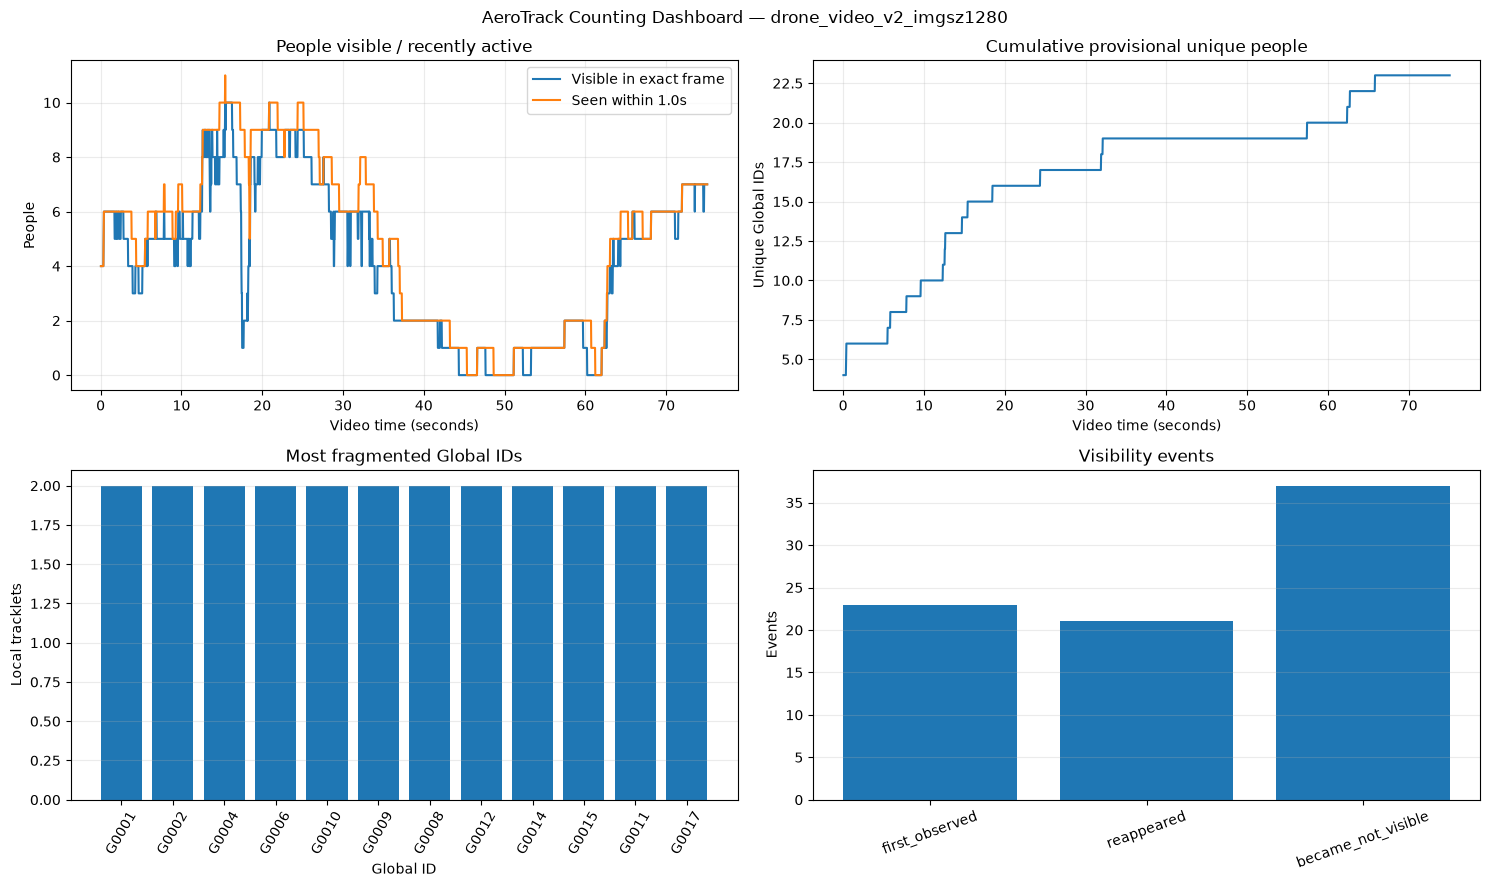

Dashboard saved: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\drone_video_v2_imgsz1280_dashboard.png


In [9]:
DASHBOARD_PATHS = []

for video_id, timeline in frame_timelines.items():
    video_log = track_log[track_log["video_id"] == video_id]
    video_events = events_df[
        events_df["video_id"] == video_id
    ] if not events_df.empty else pd.DataFrame()

    id_tracklet_counts = (
        video_log.groupby("global_id")["tracklet_key"]
        .nunique()
        .sort_values(ascending=False)
        .head(12)
    )

    event_counts = (
        video_events["event_type"].value_counts()
        if not video_events.empty
        else pd.Series(dtype=int)
    )

    fig, axes = plt.subplots(2, 2, figsize=(15, 9))

    axes[0, 0].plot(
        timeline["time_seconds"],
        timeline["visible_unique_global_ids"],
        label="Visible in exact frame"
    )
    axes[0, 0].plot(
        timeline["time_seconds"],
        timeline["active_within_grace"],
        label=f"Seen within {VISIBILITY_GRACE_SECONDS:.1f}s"
    )
    axes[0, 0].set_title("People visible / recently active")
    axes[0, 0].set_xlabel("Video time (seconds)")
    axes[0, 0].set_ylabel("People")
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.25)

    axes[0, 1].plot(
        timeline["time_seconds"],
        timeline["cumulative_unique_global_ids"]
    )
    axes[0, 1].set_title("Cumulative provisional unique people")
    axes[0, 1].set_xlabel("Video time (seconds)")
    axes[0, 1].set_ylabel("Unique Global IDs")
    axes[0, 1].grid(True, alpha=0.25)

    if not id_tracklet_counts.empty:
        axes[1, 0].bar(
            id_tracklet_counts.index.astype(str),
            id_tracklet_counts.values
        )
        axes[1, 0].tick_params(axis="x", rotation=60)
    axes[1, 0].set_title("Most fragmented Global IDs")
    axes[1, 0].set_xlabel("Global ID")
    axes[1, 0].set_ylabel("Local tracklets")
    axes[1, 0].grid(axis="y", alpha=0.25)

    event_order = [
        "first_observed",
        "reappeared",
        "became_not_visible"
    ]
    event_values = [int(event_counts.get(key, 0)) for key in event_order]

    axes[1, 1].bar(event_order, event_values)
    axes[1, 1].set_title("Visibility events")
    axes[1, 1].set_ylabel("Events")
    axes[1, 1].tick_params(axis="x", rotation=20)
    axes[1, 1].grid(axis="y", alpha=0.25)

    fig.suptitle(f"AeroTrack Counting Dashboard — {video_id}")
    fig.tight_layout()

    dashboard_path = PART8_DIR / f"{video_id}_dashboard.png"
    fig.savefig(dashboard_path, dpi=150, bbox_inches="tight")
    DASHBOARD_PATHS.append(dashboard_path)

    plt.show()
    print("Dashboard saved:", dashboard_path)
    plt.close(fig)

## Section 10 — Export the counting timeline and visibility events

The timeline is useful for later analysis or for building a separate user interface. It contains exact visible counts, grace-period activity and cumulative unique IDs for every processed frame.

In [10]:
TIMELINE_PATH = PART8_DIR / "frame_count_timeline.csv"
EVENTS_PATH = PART8_DIR / "visibility_events.csv"
VIDEO_SUMMARY_PATH = PART8_DIR / "video_count_summary.csv"
COMBINED_SUMMARY_PATH = PART8_DIR / "combined_count_summary.csv"
REGISTRY_WITH_COUNTS_PATH = PART8_DIR / "global_identity_registry_with_counts.csv"

timeline_df.to_csv(TIMELINE_PATH, index=False)
events_df.to_csv(EVENTS_PATH, index=False)
video_summary_df.to_csv(VIDEO_SUMMARY_PATH, index=False)
combined_summary.to_csv(COMBINED_SUMMARY_PATH, index=False)

# Join counting/observation history back to the Part 7 registry.
registry_with_counts = registry.merge(
    identity_history[
        [
            "global_id", "video_count", "local_tracklets",
            "detection_observations", "identity_scope"
        ]
    ],
    on="global_id",
    how="left"
)

registry_with_counts.to_csv(
    REGISTRY_WITH_COUNTS_PATH,
    index=False
)

print("Saved:")
for path in [
    TIMELINE_PATH,
    EVENTS_PATH,
    VIDEO_SUMMARY_PATH,
    COMBINED_SUMMARY_PATH,
    REGISTRY_WITH_COUNTS_PATH
]:
    print(path)

Saved:
C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\frame_count_timeline.csv
C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\visibility_events.csv
C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\video_count_summary.csv
C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\combined_count_summary.csv
C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\global_identity_registry_with_counts.csv


## Section 11 — Create annotated videos with live counts and Global IDs

The video overlay displays:
- Provisional Global ID (`Gxxxx`).
- Local BoT-SORT tracker ID (`Txx`).
- Exact visible people in the current frame.
- Recently active identities within the configured grace period.
- Cumulative provisional unique identities seen so far.

If a Global ID contains multiple tracklets, the label includes `PROV`.

The overlay is based on the complete Part 7 registry, so the first observation of a Global ID is counted once even if that identity is represented by multiple non-overlapping local tracklets later in the recording.

In [11]:
def stable_color(identifier):
    digest = hashlib.md5(str(identifier).encode("utf-8")).digest()
    return (
        int(70 + digest[0] % 170),
        int(70 + digest[1] % 170),
        int(70 + digest[2] % 170)
    )


ANNOTATED_PATHS = []

if WRITE_ANNOTATED_VIDEO:
    for source in VIDEO_SOURCES:
        video_id = str(source["video_id"])
        meta = video_metadata[video_id]

        video_log = track_log[
            track_log["video_id"] == video_id
        ].copy()

        timeline = frame_timelines[video_id]
        metrics_by_frame = timeline.set_index("frame").to_dict("index")

        records_by_frame = {
            int(frame_number): group
            for frame_number, group in video_log.groupby("frame")
        }

        max_local_frame = int(video_log["frame"].max())

        cap = cv2.VideoCapture(str(meta["video_path"]))
        cap.set(
            cv2.CAP_PROP_POS_MSEC,
            meta["segment_start_seconds"] * 1000
        )

        if not cap.isOpened():
            raise RuntimeError(
                f"{video_id}: could not reopen video for annotation."
            )

        output_path = PART8_DIR / f"{video_id}_counting_dashboard.mp4"

        output_fps = (
            float(ANNOTATED_VIDEO_FPS)
            if ANNOTATED_VIDEO_FPS is not None
            else meta["fps"]
        )

        writer = cv2.VideoWriter(
            str(output_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            output_fps,
            (meta["width"], meta["height"])
        )

        if not writer.isOpened():
            cap.release()
            raise RuntimeError(f"Could not create {output_path}")

        frame_number = 0
        start_render = time.time()

        while frame_number < max_local_frame:
            success, frame = cap.read()

            if not success:
                break

            frame_number += 1
            metrics = metrics_by_frame.get(frame_number, {})

            rows = records_by_frame.get(frame_number)

            if rows is not None:
                for _, row in rows.iterrows():
                    x1 = max(0, int(round(row["x1"])))
                    y1 = max(0, int(round(row["y1"])))
                    x2 = min(meta["width"] - 1, int(round(row["x2"])))
                    y2 = min(meta["height"] - 1, int(round(row["y2"])))

                    if x2 <= x1 or y2 <= y1:
                        continue

                    global_id = str(row["global_id"])
                    track_id = int(row["track_id"])
                    color = stable_color(global_id)

                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        color,
                        2
                    )

                    group_size = int(
                        identity_history.loc[
                            identity_history["global_id"] == global_id,
                            "local_tracklets"
                        ].iloc[0]
                    ) if (
                        global_id in set(identity_history["global_id"])
                    ) else 1

                    label = f"{global_id} | T{track_id}"
                    if group_size > 1:
                        label += " PROV"

                    font_scale = max(
                        0.45,
                        min(0.75, meta["width"] / 5000)
                    )

                    cv2.putText(
                        frame,
                        label,
                        (x1, max(22, y1 - 7)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        font_scale,
                        color,
                        2,
                        cv2.LINE_AA
                    )

            visible_count = int(
                metrics.get("visible_unique_global_ids", 0)
            )
            active_count = int(
                metrics.get("active_within_grace", 0)
            )
            cumulative_count = int(
                metrics.get("cumulative_unique_global_ids", 0)
            )

            # Draw a compact information panel.
            panel_lines = [
                f"AeroTrack | {video_id}",
                f"Visible now: {visible_count}",
                f"Recently active: {active_count}",
                f"Unique IDs seen: {cumulative_count}",
                "Global IDs are provisional"
            ]

            panel_x, panel_y = 20, 20
            font_scale = max(0.55, min(0.95, meta["width"] / 4000))
            line_height = int(32 * font_scale)
            panel_width = int(meta["width"] * 0.24)
            panel_height = line_height * len(panel_lines) + 20

            overlay = frame.copy()
            cv2.rectangle(
                overlay,
                (panel_x, panel_y),
                (panel_x + panel_width, panel_y + panel_height),
                (0, 0, 0),
                -1
            )
            frame = cv2.addWeighted(overlay, 0.55, frame, 0.45, 0)

            for line_index, text in enumerate(panel_lines):
                text_y = panel_y + 12 + (line_index + 1) * line_height

                cv2.putText(
                    frame,
                    text,
                    (panel_x + 12, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale,
                    (255, 255, 255),
                    2,
                    cv2.LINE_AA
                )

            writer.write(frame)

            if frame_number % 200 == 0:
                print(
                    f"{video_id}: rendered {frame_number}/{max_local_frame} frames"
                )

        cap.release()
        writer.release()

        ANNOTATED_PATHS.append(output_path)

        print(
            f"{video_id}: annotated video saved to {output_path} | "
            f"render time {time.time() - start_render:.1f}s"
        )

print("Annotated videos created:", len(ANNOTATED_PATHS))

drone_video_v2_imgsz1280: rendered 200/2250 frames
drone_video_v2_imgsz1280: rendered 400/2250 frames
drone_video_v2_imgsz1280: rendered 600/2250 frames
drone_video_v2_imgsz1280: rendered 800/2250 frames
drone_video_v2_imgsz1280: rendered 1000/2250 frames
drone_video_v2_imgsz1280: rendered 1200/2250 frames
drone_video_v2_imgsz1280: rendered 1400/2250 frames
drone_video_v2_imgsz1280: rendered 1600/2250 frames
drone_video_v2_imgsz1280: rendered 1800/2250 frames
drone_video_v2_imgsz1280: rendered 2000/2250 frames
drone_video_v2_imgsz1280: rendered 2200/2250 frames
drone_video_v2_imgsz1280: annotated video saved to C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\drone_video_v2_imgsz1280_counting_dashboard.mp4 | render time 226.0s
Annotated videos created: 1


## Section 12 — Inspect final counts and visibility events

This section shows the final per-video count, maximum simultaneous visible people, cumulative unique identities and visibility event counts.

Remember:
- `visible_people_final_frame` is the exact count on the last logged frame.
- `recently_active_final_frame` includes people detected within the grace period.
- `cumulative_unique_final` is the number of distinct provisional Global IDs observed during the processed segment.

In [12]:
print("PER-VIDEO SUMMARY")
display(video_summary_df)

print("COMBINED SUMMARY")
display(combined_summary)

print("MOST FRAGMENTED IDENTITIES")
display(
    identity_history.sort_values(
        ["local_tracklets", "detection_observations"],
        ascending=False
    ).head(20)
)

print("VISIBILITY EVENT EXAMPLES")
display(events_df.head(30))

print("ANNOTATED VIDEO OUTPUTS")
for path in ANNOTATED_PATHS:
    print(path)

PER-VIDEO SUMMARY


,video_id,detection_observations,local_tracklets,tracklets_missing_registry,provisional_unique_global_ids,multi_tracklet_global_groups,visible_people_final_frame,recently_active_final_frame,max_concurrent_visible_people,average_visible_people,cumulative_unique_final,first_observed_events,reappearance_events,became_not_visible_events
0,drone_video_v2_imgsz1280,9616,35,0,23,12,7,7,10,4.273778,23,23,21,37


COMBINED SUMMARY


,videos_processed,local_tracklets_total,sum_of_per_video_global_ids,deduplicated_global_ids_across_videos,cross_video_deduplication_difference,unmapped_tracklets,count_status
0,1,35,23,23,0,0,provisional_global_identity_count


MOST FRAGMENTED IDENTITIES


,global_id,videos,video_count,local_tracklets,tracker_ids,first_seen_seconds,last_seen_seconds,detection_observations,video_tracklet_keys,identity_scope
1,G0002,drone_video_v2_imgsz1280,1,2,"2, 102",0.033367,75.075000,1333,drone_video_v2_imgsz1280::track_102 | drone_vi...,multi_tracklet_provisional
14,G0015,drone_video_v2_imgsz1280,1,2,"25, 110",15.415400,75.075000,962,drone_video_v2_imgsz1280::track_110 | drone_vi...,multi_tracklet_provisional
8,G0009,drone_video_v2_imgsz1280,1,2,"13, 118",7.841167,75.075000,923,drone_video_v2_imgsz1280::track_118 | drone_vi...,multi_tracklet_provisional
11,G0012,drone_video_v2_imgsz1280,1,2,"21, 40",12.579233,44.310933,880,drone_video_v2_imgsz1280::track_21 | drone_vid...,multi_tracklet_provisional
0,G0001,drone_video_v2_imgsz1280,1,2,"1, 114",0.033367,75.075000,802,drone_video_v2_imgsz1280::track_1 | drone_vide...,multi_tracklet_provisional
7,G0008,drone_video_v2_imgsz1280,1,2,"9, 42",5.839167,36.002633,795,drone_video_v2_imgsz1280::track_42 | drone_vid...,multi_tracklet_provisional
13,G0014,drone_video_v2_imgsz1280,1,2,"24, 66",14.714700,42.208833,569,drone_video_v2_imgsz1280::track_24 | drone_vid...,multi_tracklet_provisional
5,G0006,drone_video_v2_imgsz1280,1,2,"6, 107",0.400400,75.075000,437,drone_video_v2_imgsz1280::track_107 | drone_vi...,multi_tracklet_provisional
3,G0004,drone_video_v2_imgsz1280,1,2,"4, 98",0.033367,60.193467,392,drone_video_v2_imgsz1280::track_4 | drone_vide...,multi_tracklet_provisional
10,G0011,drone_video_v2_imgsz1280,1,2,"19, 41",12.345667,27.594233,347,drone_video_v2_imgsz1280::track_19 | drone_vid...,multi_tracklet_provisional


VISIBILITY EVENT EXAMPLES


,video_id,global_id,event_type,frame,time_seconds,episode_number
0,drone_video_v2_imgsz1280,G0001,first_observed,1,0.033367,1
1,drone_video_v2_imgsz1280,G0002,first_observed,1,0.033367,1
2,drone_video_v2_imgsz1280,G0003,first_observed,1,0.033367,1
3,drone_video_v2_imgsz1280,G0004,first_observed,1,0.033367,1
4,drone_video_v2_imgsz1280,G0005,first_observed,11,0.367033,1
5,drone_video_v2_imgsz1280,G0006,first_observed,12,0.400400,1
6,drone_video_v2_imgsz1280,G0006,became_not_visible,115,3.837167,1
7,drone_video_v2_imgsz1280,G0005,became_not_visible,132,4.404400,1
8,drone_video_v2_imgsz1280,G0007,first_observed,165,5.505500,1
9,drone_video_v2_imgsz1280,G0008,first_observed,175,5.839167,1


ANNOTATED VIDEO OUTPUTS
C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\drone_video_v2_imgsz1280_counting_dashboard.mp4


## Section 13 — Save the final experiment summary

The JSON summary records the settings and counts, including the grace period. This makes the result reproducible and easier to compare with later experiments.

In [13]:
summary = {
    "videos_processed": [str(x["video_id"]) for x in VIDEO_SOURCES],
    "visibility_grace_seconds": VISIBILITY_GRACE_SECONDS,
    "local_tracklets": int(track_log["tracklet_key"].nunique()),
    "tracklets_missing_registry": int(
        track_log.loc[track_log["is_unmapped"], "tracklet_key"].nunique()
    ),
    "provisional_global_ids_across_configured_videos": int(
        track_log["global_id"].nunique()
    ),
    "sum_of_per_video_provisional_global_ids": int(
        video_summary_df["provisional_unique_global_ids"].sum()
    ),
    "video_summaries": video_summary_df.to_dict(orient="records"),
    "outputs": {
        "timeline": str(TIMELINE_PATH),
        "events": str(EVENTS_PATH),
        "identity_history": str(IDENTITY_HISTORY_PATH),
        "registry_with_counts": str(REGISTRY_WITH_COUNTS_PATH),
        "annotated_videos": [str(path) for path in ANNOTATED_PATHS],
        "dashboards": [str(path) for path in DASHBOARD_PATHS]
    },
    "note": (
        "Global identities and unique-person counts are provisional. "
        "Visibility gaps are not proof of physical entry or exit. "
        "Cross-video deduplication depends on unvalidated Part 7 cross-video "
        "ReID links."
    )
}

SUMMARY_PATH = PART8_DIR / "counting_experiment_summary.json"

with open(SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("Summary saved:", SUMMARY_PATH)
display(pd.DataFrame([{
    "videos": len(summary["videos_processed"]),
    "local_tracklets": summary["local_tracklets"],
    "provisional_global_ids": summary[
        "provisional_global_ids_across_configured_videos"
    ],
    "unmapped_tracklets": summary["tracklets_missing_registry"],
    "visibility_grace_seconds": summary["visibility_grace_seconds"]
}]))

Summary saved: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\counting_experiment_summary.json


,videos,local_tracklets,provisional_global_ids,unmapped_tracklets,visibility_grace_seconds
0,1,35,23,0,1.0


## Section 14 — Optional: display an annotated video inside Jupyter

If the output file is large, open it directly from the `outputs/<video_id>/part8_counting_dashboard/` folder instead of embedding it in the notebook.

In [14]:
if ANNOTATED_PATHS:
    print("Annotated video:", ANNOTATED_PATHS[0])
    display(Video(str(ANNOTATED_PATHS[0]), embed=False, width=1000))
else:
    print("No annotated video was generated.")

Annotated video: C:\Users\anyan\Desktop\AeroTrack_clude\outputs\drone_video_v2_imgsz1280\part8_counting_dashboard\drone_video_v2_imgsz1280_counting_dashboard.mp4


## Section 15 — What to send back

Please share:

1. The `video_summary_df` output from Section 7/12.
2. The combined summary from Section 7/12.
3. A screenshot of the counting dashboard.
4. A short clip or screenshot of the annotated video showing the live count panel.
5. The first 20 rows of `identity_history.csv`, especially Global IDs with multiple local tracklets.

Main files saved under `outputs/<video_id>/part8_counting_dashboard/`:
- `frame_count_timeline.csv`
- `visibility_events.csv`
- `video_count_summary.csv`
- `combined_count_summary.csv`
- `identity_history.csv`
- `global_identity_registry_with_counts.csv`
- `<video_id>_dashboard.png`
- `<video_id>_counting_dashboard.mp4`
- `counting_experiment_summary.json`

## Part 8 conclusion

AeroTrack now has a basic counting layer built on the global identity registry. It separates exact frame visibility, recently active people, and cumulative provisional unique identities.

The counts are only as reliable as the global identity assignments from Part 7. The next improvements should be driven by the annotated video and identity-history results, not by another detector training run.